## 1. Setup and configuration

In [16]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# ----- paths -----------------------------------------------------------------
DATA_PATH = os.environ.get("DATA_PATH", "/content/Dataset_jotpars.csv")
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", ".")
CLEAN_PATH = os.path.join(OUTPUT_DIR, "cleaned_jobs.csv")
DOWNLOAD_CLEANED_CSV = True      # triggers a browser download when running in Google Colab

# ----- recommender settings --------------------------------------------------
MIN_SKILLS = 3                   # brief: minimum of three user inputs
TOP_N = 3                        # brief: Top-3 career paths
SKILL_WEIGHT = 0.8               # weight of skill similarity in the final score
EXPERIENCE_WEIGHT = 0.2          # weight of experience closeness in the final score
EXPERIENCE_TOLERANCE = 1         # hide roles asking > user experience + tolerance years
RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})
PRIMARY, ACCENT = "#3b6ea5", "#c8553d"

## 2. Concept check — why TF-IDF + cosine similarity?

The brief builds the engine in three upgrades. A tiny three-role example makes each one visible:

1. **Binary overlap (Jaccard)** treats every shared tag equally, including generic words such as *software*.
2. **TF-IDF** gives a generic word an IDF of `log(N / df) = 0` (it appears in every role) and rewards rare, specific skills.
3. **Cosine similarity** compares *orientation* rather than size, so a role with a long description is not punished.

In [17]:
toy_roles = {
    "Data Scientist":    "python sql machine learning data analysis software",
    "DevOps Engineer":   "aws docker kubernetes cicd linux software",
    "Backend Developer": "java sql apis python software",
}
toy_user = "python sql machine learning software".split()

tokens = {role: text.split() for role, text in toy_roles.items()}
vocab = sorted({t for words in tokens.values() for t in words})
N = len(tokens)
df_count = {t: sum(t in words for words in tokens.values()) for t in vocab}
idf = {t: np.log(N / df_count[t]) for t in vocab}                       # IDF = log(N / df)
tfidf_toy = pd.DataFrame(
    {role: [words.count(t) / len(words) * idf[t] for t in vocab] for role, words in tokens.items()},
    index=vocab,
)                                                                        # TF = count / length
user_vec = np.array([toy_user.count(t) / len(toy_user) * idf[t] for t in vocab])

def cosine(a, b):
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / denom) if denom else 0.0

comparison = pd.DataFrame({
    "jaccard (binary)": {role: len(set(toy_user) & set(w)) / len(set(toy_user) | set(w)) for role, w in tokens.items()},
    "cosine (TF-IDF)":  {role: cosine(user_vec, tfidf_toy[role].values) for role in tokens},
}).round(3)

print("IDF of the generic word 'software':", round(idf["software"], 3), "(appears in every role -> no weight)")
print("IDF of the specific word 'kubernetes':", round(idf["kubernetes"], 3))
display(comparison.sort_values("cosine (TF-IDF)", ascending=False))

IDF of the generic word 'software': 0.0 (appears in every role -> no weight)
IDF of the specific word 'kubernetes': 1.099


,jaccard (binary),cosine (TF-IDF)
Data Scientist,0.714,0.729
Backend Developer,0.429,0.120
DevOps Engineer,0.100,0.000


## 3. Data loading and audit

Before cleaning, the raw file is audited for shape, data types, missing values, duplicates and empty text.

In [18]:
REQUIRED_COLUMNS = ["name", "requirment", "description", "salary_range", "experience"]

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}'. Upload Dataset_jotpars.csv to Colab "
        "(or set the DATA_PATH environment variable) and re-run this cell."
    )

# Added on_bad_lines='skip' or quoting=3 to handle unclosed quotes causing EOF exceptions
raw = pd.read_csv(DATA_PATH, encoding="latin1", on_bad_lines="skip")
missing_cols = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
assert not missing_cols, f"Dataset is missing expected columns: {missing_cols}"

print("Shape            :", raw.shape)
print("Columns          :", raw.columns.tolist())
print("Duplicate rows   :", int(raw.duplicated().sum()))
print("Unique job titles:", raw["name"].nunique())
print("Unique experience values:", raw["experience"].nunique())
display(raw.head())
raw.info()

Shape            : (8797, 5)
Columns          : ['name', 'requirment', 'description', 'experience', 'salary_range']
Duplicate rows   : 1305
Unique job titles: 254
Unique experience values: 21


,name,requirment,description,experience,salary_range
0,.net Web Developer,"r2 , soa , t-sql , database , security , asp.net , mvc , c# , solution...",Job Description Job Description:# Understand project vision and objectives from...,2.0,106k-124k
1,.net Web Developer,"software development , satellite , android developer",Job Description A Leadiing Software Development CompanyClick here for more deta...,2.0,57k-60k
2,.net Web Developer,"hibernate , java developer , spring , spring mvc","Job Description B.A.T. provides a world of opportunities to the Software, Domai...",1.0,107k-118k
3,.net Web Developer,"css , team player , ajax , javascript , sql , linq , xml , web developer...",Job Description .Net Web Developer (for Chennai India region)Efforts Solutions...,1.0,68k-70k
4,.net Web Developer,"css , html5 , ajax , oop , windows platform , devops , web developer , a...",Job Description Job Description Develop and maintain high-quality software prod...,5.0,46k-48k


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8797 entries, 0 to 8796
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          8797 non-null   object 
 1   requirment    8797 non-null   object 
 2   description   8797 non-null   object 
 3   experience    8797 non-null   float64
 4   salary_range  8797 non-null   object 
dtypes: float64(1), object(4)
memory usage: 343.8+ KB


In [19]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isnull().sum(),
    "empty_strings": [int(raw[c].astype(str).str.strip().eq("").sum()) for c in raw.columns],
    "unique": raw.nunique(),
})
display(quality)

duplicate_rows = raw[raw.duplicated(keep=False)]
print(f"Rows involved in duplicates: {len(duplicate_rows)}")
if len(duplicate_rows):
    display(duplicate_rows.head(10))

print("\nRequirement length (characters):")
display(raw["requirment"].astype(str).str.len().describe().round(1).to_frame("requirment"))
print("Description length (characters):")
display(raw["description"].astype(str).str.len().describe().round(1).to_frame("description"))

,dtype,missing,empty_strings,unique
name,object,0,0,254
requirment,object,0,0,5494
description,object,0,0,5919
experience,float64,0,0,21
salary_range,object,0,0,2822


Rows involved in duplicates: 2354


,name,requirment,description,experience,salary_range
590,Android Developer,"fundamentals , algorithms , storage , java , data structures",Job Description Required Experience : 4-6 years of experience working with Andr...,2.0,55k-63k
591,Android Developer,"algorithms , software design , memory management , mysql , data structures , ...",Job Description Skills Required: Min 2 years of experience.Experience in develo...,1.0,56k-60k
592,Android Developer,"telerik , eclipse , java , debugging , bluetooth low energy , api , softwa...",Job Description No of Position : 2Experience : 2-4 Yrs.Qualification : MCA/BE.I...,4.0,45k-48k
593,Android Developer,"com , security , mobile developer",Job Description NOTE: Company keep educational certificate for 1 year as securi...,3.0,42k-45k
594,Android Developer,"php , storage , java , xml , json , rest , mobile , eclipse , soap",Job Description Android App Developer As part of our expansion and consolidatio...,3.0,51k-51k
595,Android Developer,"c , os , computer programming , operating system , mobile , java , git ...","Job Description First, the question what exactly is android? Android is an oper...",5.0,59k-59k
596,Android Developer,"c , os , kernel , java",Job Description Key Accountabilities/Responsibilities:Feature development and m...,1.0,55k-64k
597,Android Developer,"java , php , Unit Testing , AWS",Job Description Responsibilities: Create and work on software projects to deliv...,2.0,41k-59k
598,Android Developer,"rest , css , imaging , javascript , gradle , java , mvvm , json , debu...",Job Description Work on Android native applications and applications based on C...,4.0,42k-51k
599,Android Developer,"database management system , eclipse , j2me , java , j2ee , mysql",Job Description Job Description : Host2unlimited is looking for Android Applica...,1.0,60k-61k



Requirement length (characters):


,requirment
count,8797.0
mean,125.5
std,64.5
min,1.0
25%,76.0
50%,114.0
75%,165.0
max,399.0


Description length (characters):


,description
count,8797.0
mean,1540.6
std,1184.5
min,248.0
25%,719.0
50%,1216.0
75%,1955.0
max,7816.0


## 4. Data cleaning

Steps: rename columns → normalise whitespace → coerce experience to numbers → drop duplicates and unusable rows →
parse salary ranges into numeric `salary_min` / `salary_max` (supports `106k-124k`, `1.5 lac-2 lac`, `30-40k`).
The raw data is never modified; a cleaned copy is saved as `cleaned_jobs.csv`.

In [20]:
TEXT_COLUMNS = ["job_title", "requirements", "description", "salary_range"]
UNIT_MULTIPLIER = {"k": 1_000, "lac": 100_000, "lakh": 100_000}


def clean_text(value) -> str:
    """Return a whitespace-normalised string ('' for missing values)."""
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def parse_salary(value) -> tuple:
    """Parse ranges such as '106k-124k', '1.5 lac-2 lac' or '30-40k' into (min, max)."""
    found = re.findall(r"(\d+(?:\.\d+)?)\s*(k|lac|lakh)?", str(value).lower())
    if len(found) != 2 or not any(unit for _, unit in found):
        return np.nan, np.nan
    shared_unit = next(unit for _, unit in found if unit)          # '30-40k' -> both in k
    low, high = (float(num) * UNIT_MULTIPLIER[unit or shared_unit] for num, unit in found)
    return low, high


def clean_jobs(raw_df: pd.DataFrame):
    """Return (clean_df, report) for the raw job-postings table."""
    df = raw_df.rename(columns={"name": "job_title", "requirment": "requirements"}).copy()
    for column in TEXT_COLUMNS:
        df[column] = df[column].map(clean_text)
    df["experience"] = pd.to_numeric(df["experience"], errors="coerce")

    report = {"raw_rows": len(df)}
    df = df.drop_duplicates()
    report["after_deduplication"] = len(df)
    df = df[(df["job_title"] != "") & (df["requirements"] != "")].reset_index(drop=True)
    report["after_removing_empty_text"] = len(df)

    parsed = df["salary_range"].map(parse_salary)
    df["salary_min"] = parsed.map(lambda pair: pair[0])
    df["salary_max"] = parsed.map(lambda pair: pair[1])
    df["salary_mid"] = (df["salary_min"] + df["salary_max"]) / 2

    report["unique_roles"] = df["job_title"].nunique()
    report["missing_experience"] = int(df["experience"].isna().sum())
    report["unparsed_salary"] = int(df["salary_min"].isna().sum())
    return df, report


jobs, cleaning_report = clean_jobs(raw)
display(pd.Series(cleaning_report, name="count").to_frame())

unparsed = jobs.loc[jobs["salary_min"].isna(), "salary_range"].value_counts().head(8)
if len(unparsed):
    print("Most common salary values that could not be parsed (kept as 'not disclosed'):")
    display(unparsed.to_frame("postings"))

jobs.to_csv(CLEAN_PATH, index=False)
print(f"Cleaned dataset saved to {CLEAN_PATH}")
if DOWNLOAD_CLEANED_CSV:
    try:
        from google.colab import files          # only available in Google Colab
        files.download(CLEAN_PATH)
    except ImportError:
        pass
display(jobs.head())

,count
raw_rows,8797
after_deduplication,7492
after_removing_empty_text,7492
unique_roles,245
missing_experience,0
unparsed_salary,0


Cleaned dataset saved to ./cleaned_jobs.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,job_title,requirements,description,experience,salary_range,salary_min,salary_max,salary_mid
0,.net Web Developer,"r2 , soa , t-sql , database , security , asp.net , mvc , c# , solution architect , asp...",Job Description Job Description:# Understand project vision and objectives from users ...,2.0,106k-124k,106000.0,124000.0,115000.0
1,.net Web Developer,"software development , satellite , android developer",Job Description A Leadiing Software Development CompanyClick here for more details of ...,2.0,57k-60k,57000.0,60000.0,58500.0
2,.net Web Developer,"hibernate , java developer , spring , spring mvc","Job Description B.A.T. provides a world of opportunities to the Software, Domain and E...",1.0,107k-118k,107000.0,118000.0,112500.0
3,.net Web Developer,"css , team player , ajax , javascript , sql , linq , xml , web developer , asp.net , ....",Job Description .Net Web Developer (for Chennai India region)Efforts Solutions IT is l...,1.0,68k-70k,68000.0,70000.0,69000.0
4,.net Web Developer,"css , html5 , ajax , oop , windows platform , devops , web developer , asp.net , clien...",Job Description Job Description Develop and maintain high-quality software products th...,5.0,46k-48k,46000.0,48000.0,47000.0


## 5. Exploratory data analysis

### 5.1 Job titles

Postings per job title:


,postings
count,245.00
mean,30.58
std,92.52
min,1.00
25%,1.00
50%,3.00
75%,16.00
max,929.00


Titles with a single posting: 82 of 245


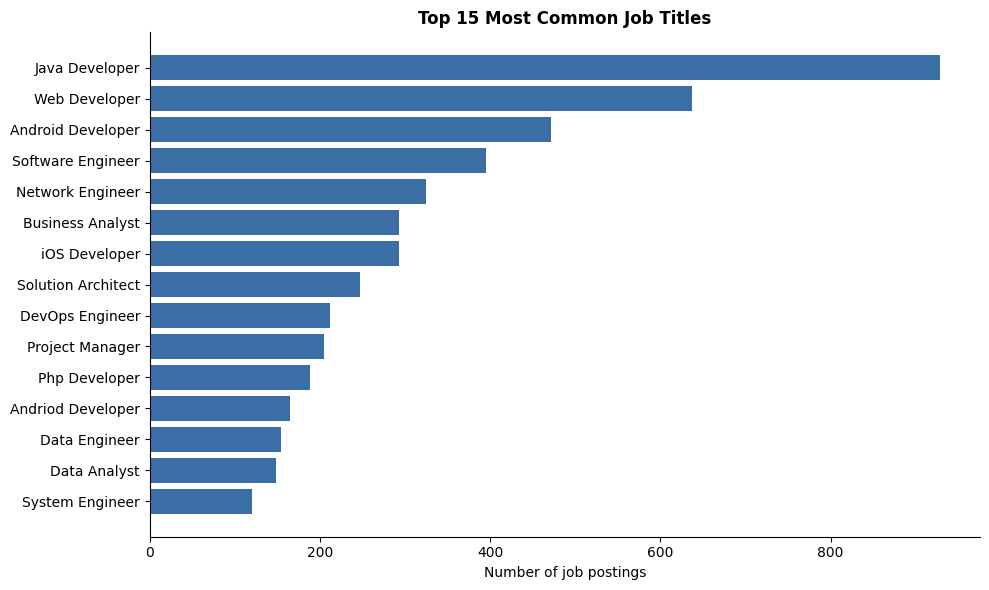

In [21]:
title_counts = jobs["job_title"].value_counts()
print("Postings per job title:")
display(title_counts.describe().round(2).to_frame("postings"))
print(f"Titles with a single posting: {(title_counts == 1).sum()} of {len(title_counts)}")

top_titles = title_counts.head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_titles.index, top_titles.values, color=PRIMARY)
ax.set_title("Top 15 Most Common Job Titles")
ax.set_xlabel("Number of job postings")
plt.tight_layout()
plt.show()

### 5.2 Experience, requirement length and description length

,experience,requirements_length,description_length
count,7492.00,7492.00,7492.00
mean,3.30,107.84,1536.58
std,1.94,55.11,1183.61
min,0.00,1.00,240.00
25%,2.00,65.00,707.75
50%,3.00,98.00,1211.50
75%,5.00,142.00,1953.00
max,15.00,343.00,7797.00


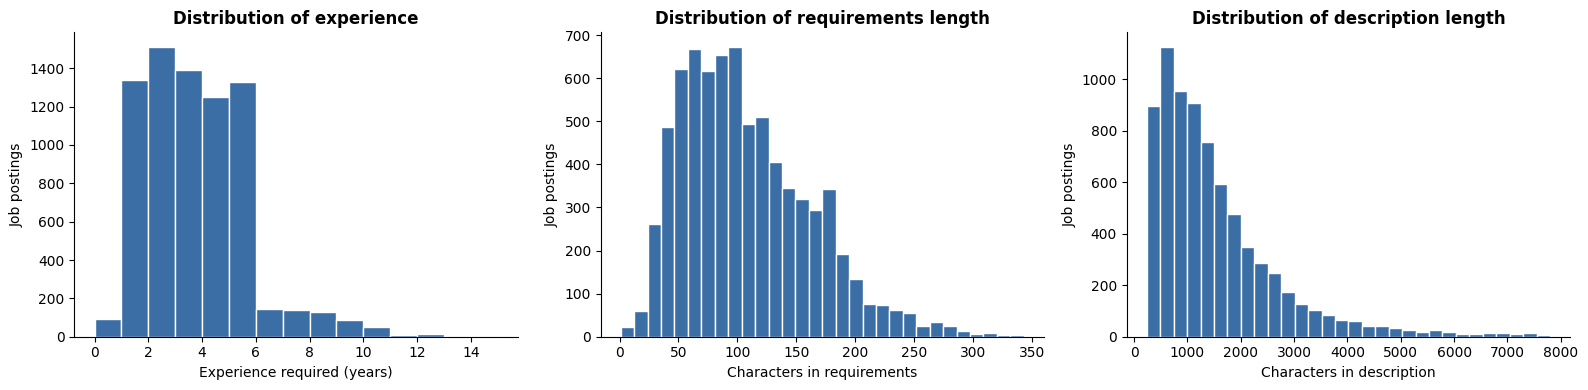

In [22]:
jobs["requirements_length"] = jobs["requirements"].str.len()
jobs["description_length"] = jobs["description"].str.len()

display(jobs[["experience", "requirements_length", "description_length"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
panels = [
    ("experience", "Experience required (years)", 15),
    ("requirements_length", "Characters in requirements", 30),
    ("description_length", "Characters in description", 30),
]
for ax, (column, label, bins) in zip(axes, panels):
    ax.hist(jobs[column].dropna(), bins=bins, color=PRIMARY, edgecolor="white")
    ax.set_xlabel(label)
    ax.set_ylabel("Job postings")
    ax.set_title(f"Distribution of {column.replace('_', ' ')}")
plt.tight_layout()
plt.show()

### 5.3 Salary analysis
Salaries are used exactly as published in the dataset (e.g. `k` = thousands, `lac` = 100,000); no currency conversion is applied.

Postings with a parsed salary: 7,492 of 7,492


,salary_min,salary_max,salary_mid
count,7492.0,7492.0,7492.0
mean,61792.0,77808.0,69800.0
std,124175.0,160348.0,139809.0
min,10000.0,11000.0,11000.0
25%,29000.0,37000.0,33500.0
50%,42000.0,56000.0,49500.0
75%,63000.0,79000.0,69500.0
max,1962000.0,1998000.0,1980000.0


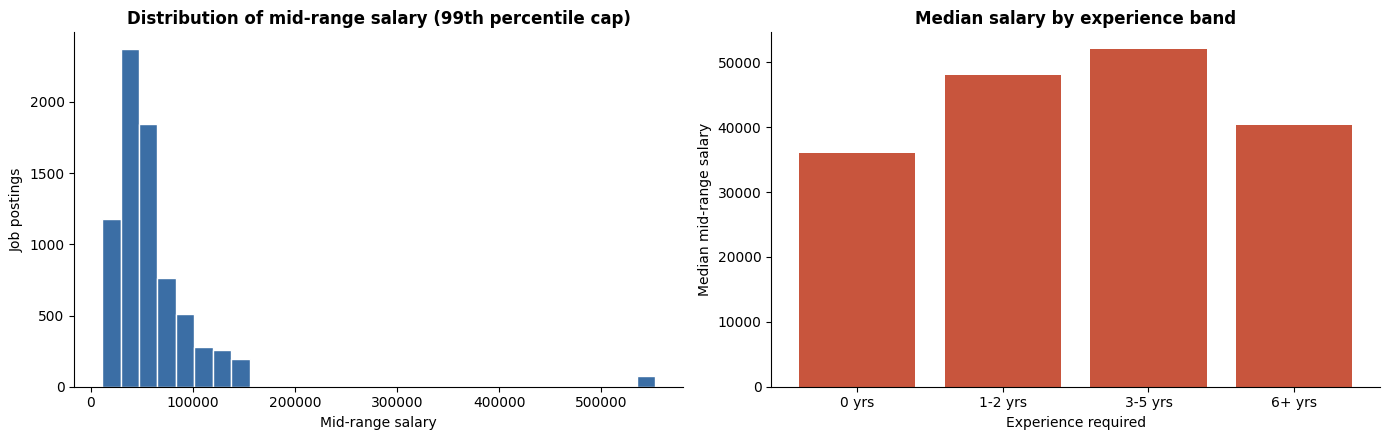

Top 10 highest-paying roles (roles with at least 3 salary-bearing postings):


,median_salary,postings
job_title,,
Lead Software Architect,1379500.0,7
Software Architect,1303250.0,56
Senior Software Architect,1282000.0,3
Software Technical Architect,1224000.0,4
Lead DevOps Engineer,145000.0,11
Embedded Software Engineer,142000.0,49
AWS Devops Engineer,139000.0,5
Staff Software Engineer,138750.0,38
Azure DevOps Engineer,138000.0,9


In [23]:
salary_known = jobs.dropna(subset=["salary_mid"])
print(f"Postings with a parsed salary: {len(salary_known):,} of {len(jobs):,}")
display(salary_known[["salary_min", "salary_max", "salary_mid"]].describe().round(0))

if len(salary_known):
    cap = salary_known["salary_mid"].quantile(0.99)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].hist(salary_known["salary_mid"].clip(upper=cap), bins=30, color=PRIMARY, edgecolor="white")
    axes[0].set_title("Distribution of mid-range salary (99th percentile cap)")
    axes[0].set_xlabel("Mid-range salary")
    axes[0].set_ylabel("Job postings")

    buckets = pd.cut(salary_known["experience"], [-0.1, 0, 2, 5, 100], labels=["0 yrs", "1-2 yrs", "3-5 yrs", "6+ yrs"])
    by_experience = salary_known.groupby(buckets, observed=True)["salary_mid"].median()
    axes[1].bar(by_experience.index.astype(str), by_experience.values, color=ACCENT)
    axes[1].set_title("Median salary by experience band")
    axes[1].set_xlabel("Experience required")
    axes[1].set_ylabel("Median mid-range salary")
    plt.tight_layout()
    plt.show()

    min_postings = 3 if (title_counts >= 3).sum() >= 10 else 1
    role_salary = (salary_known.groupby("job_title")
                   .agg(median_salary=("salary_mid", "median"), postings=("salary_mid", "size"))
                   .query("postings >= @min_postings")
                   .sort_values("median_salary", ascending=False).head(10))
    print(f"Top 10 highest-paying roles (roles with at least {min_postings} salary-bearing postings):")
    display(role_salary.round(0))

### 5.4 Technology demand
Word-boundary matching is used so that `java` does not match `javascript`, and terms such as `c++`, `c#` and `node.js` are handled correctly.

,postings,share_%
java,2552,34.1
javascript,1785,23.8
sql,1364,18.2
css,1213,16.2
html,1204,16.1
python,1155,15.4
git,1048,14.0
mysql,1018,13.6
spring,1007,13.4
php,914,12.2


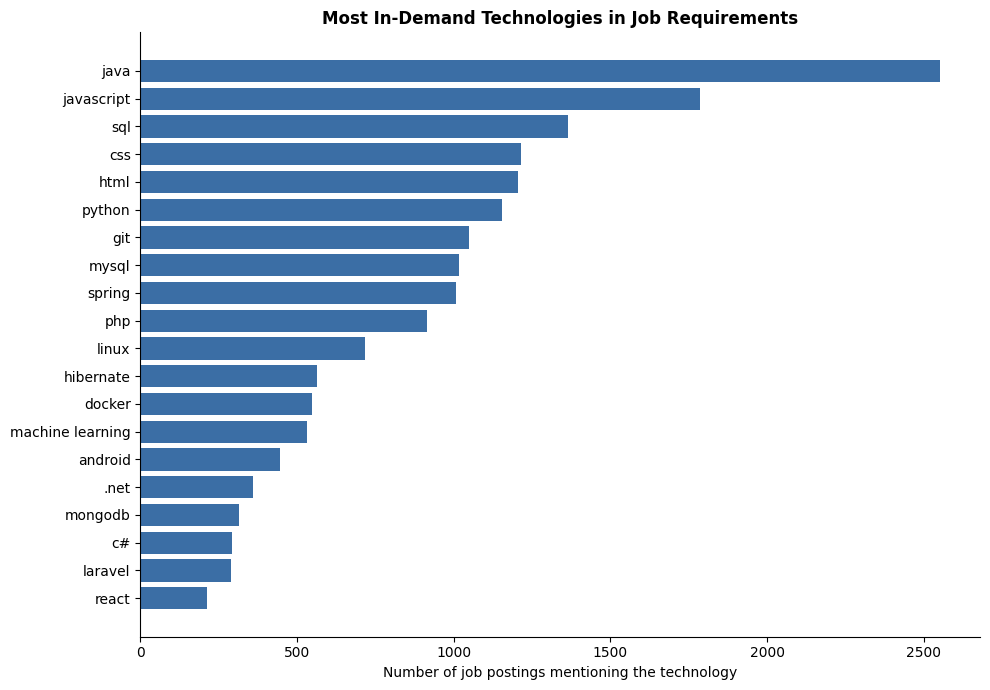

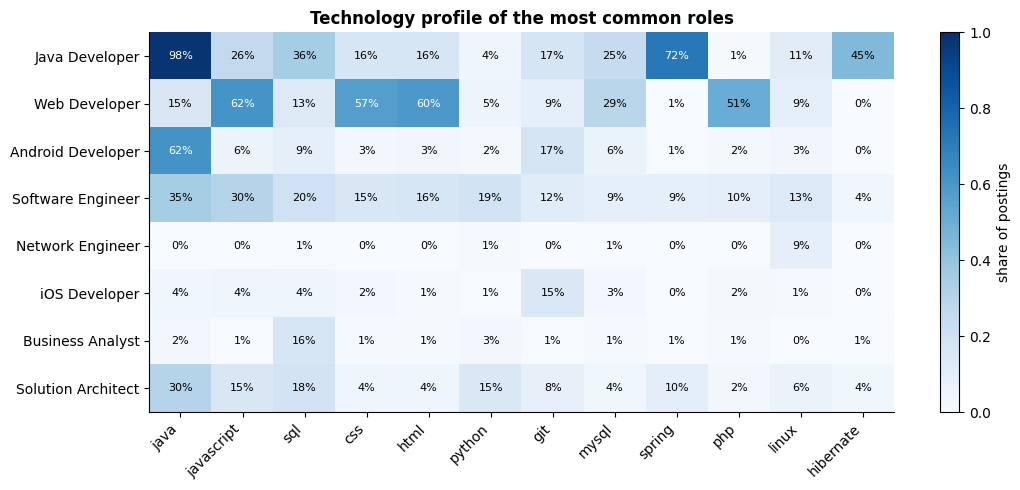

Sample requirement texts:
- .net Web Developer: r2 , soa , t-sql , database , security , asp.net , mvc , c# , solution architect , asp .net , windows , .net
- .net Web Developer: software development , satellite , android developer
- .net Web Developer: hibernate , java developer , spring , spring mvc
- .net Web Developer: css , team player , ajax , javascript , sql , linq , xml , web developer , asp.net , .net , mvc , c#.net , dhtml , asp
- .net Web Developer: css , html5 , ajax , oop , windows platform , devops , web developer , asp.net , client server , javascript , business objects , .net , ado.net , bootstrap , we


In [24]:
TECH_KEYWORDS = [
    "python", "java", "javascript", "typescript", "c++", "c#", "php", "go", "golang", "ruby", "kotlin", "swift",
    "sql", "mysql", "postgresql", "mongodb", "html", "css", "react", "angular", "vue", "node.js", "django", "flask",
    "laravel", "spring", "hibernate", ".net", "aws", "azure", "docker", "kubernetes", "linux", "git", "ci/cd",
    "rest api", "machine learning", "deep learning", "tensorflow", "pytorch", "pandas", "numpy", "scikit-learn",
    "data analysis", "tableau", "power bi", "excel", "android", "flutter",
]


def skill_pattern(term: str) -> str:
    """Regex matching `term` as a whole token (so 'java' does not match 'javascript')."""
    return rf"(?<!\w){re.escape(term)}(?!\w)"


def build_tech_flags(df: pd.DataFrame) -> pd.DataFrame:
    """Boolean matrix: does each posting mention each technology?"""
    text = df["requirements"].str.lower()
    return pd.DataFrame({t: text.str.contains(skill_pattern(t), regex=True) for t in TECH_KEYWORDS}, index=df.index)


tech_flags = build_tech_flags(jobs)
tech_demand = tech_flags.sum().sort_values(ascending=False)
tech_share = (tech_demand / len(jobs) * 100).round(1)
display(pd.DataFrame({"postings": tech_demand, "share_%": tech_share}).head(15))

top_tech = tech_demand[tech_demand > 0].head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_tech.index, top_tech.values, color=PRIMARY)
ax.set_title("Most In-Demand Technologies in Job Requirements")
ax.set_xlabel("Number of job postings mentioning the technology")
plt.tight_layout()
plt.show()

# Technology profile of the most common roles (share of that role's postings mentioning each technology)
top_roles = title_counts.head(8).index
top_techs = tech_demand.head(12).index
heat = tech_flags.loc[jobs["job_title"].isin(top_roles), top_techs].groupby(jobs["job_title"]).mean().loc[top_roles]
fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(top_techs)), top_techs, rotation=45, ha="right")
ax.set_yticks(range(len(top_roles)), top_roles)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0%}", ha="center", va="center",
                color="white" if heat.values[i, j] > 0.55 else "black", fontsize=8)
ax.set_title("Technology profile of the most common roles")
fig.colorbar(image, ax=ax, label="share of postings")
plt.tight_layout()
plt.show()

print("Sample requirement texts:")
for _, row in jobs.head(5).iterrows():
    print(f"- {row['job_title']}: {row['requirements'][:160]}")

## 6. Feature engineering

**Vector mapping:** user skills and job requirements must live in the *same vocabulary space*, otherwise the similarity math fails.

* A **custom tokenizer** keeps technology terms intact (`c++`, `c#`, `node.js`, `scikit-learn`) and removes trailing punctuation
  (the original pattern kept the full stop in `python.`, which silently broke matches at the end of sentences).
* **Unigrams + bigrams** keep `machine learning` as one concept.
* Roles are built by **concatenating the requirements of all postings** with the same title; experience and salary use the **median**.

In [25]:
_TOKEN_PATTERN = re.compile(r"\w+(?:[.\-]\w+)*(?:\+\+|#)?")


def preprocess_text(text) -> str:
    """Lower-case and collapse whitespace."""
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def tokenize(text: str) -> list:
    """Tokenizer that keeps tech terms such as 'c++', 'c#' and 'node.js' intact."""
    return _TOKEN_PATTERN.findall(text.lower())


sample_sentence = "Experience with C++, C# and Node.js; Python. Strong machine learning skills."
default_tokens = TfidfVectorizer().build_analyzer()(sample_sentence)
print("Default sklearn tokens:", default_tokens)
print("Custom tokenizer      :", tokenize(sample_sentence))

Default sklearn tokens: ['experience', 'with', 'and', 'node', 'js', 'python', 'strong', 'machine', 'learning', 'skills']
Custom tokenizer      : ['experience', 'with', 'c++', 'c#', 'and', 'node.js', 'python', 'strong', 'machine', 'learning', 'skills']


In [26]:
def build_role_profiles(df: pd.DataFrame) -> pd.DataFrame:
    """One row per job title with combined requirements and median experience / salary."""
    roles = (
        df.groupby("job_title")
        .agg(requirements=("requirements", " ".join),
             experience=("experience", "median"),
             salary_min=("salary_min", "median"),
             salary_max=("salary_max", "median"),
             postings=("job_title", "size"))
        .reset_index()
    )
    roles["_text"] = roles["requirements"].map(preprocess_text)
    return roles


role_profiles = build_role_profiles(jobs)
explore_vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                                     ngram_range=(1, 2), sublinear_tf=True)
explore_matrix = explore_vectorizer.fit_transform(role_profiles["_text"])
print("Role profiles (items):", len(role_profiles))
print("TF-IDF matrix shape  :", explore_matrix.shape, "(roles x vocabulary terms)")
print("Matrix density       :", f"{explore_matrix.nnz / np.prod(explore_matrix.shape):.2%}")

# Highest-weighted terms for the five most frequent roles
terms = np.array(explore_vectorizer.get_feature_names_out())
top_idx = role_profiles["postings"].nlargest(5).index
distinct = {role_profiles.at[i, "job_title"]:
            ", ".join(terms[np.argsort(explore_matrix[i].toarray().ravel())[::-1][:8]]) for i in top_idx}
display(pd.Series(distinct, name="highest TF-IDF terms").to_frame())

Role profiles (items): 245
TF-IDF matrix shape  : (245, 21394) (roles x vocabulary terms)
Matrix density       : 1.12%


,highest TF-IDF terms
Java Developer,"java developer, hibernate java, developer eclipse, gwt, struts, hibernate ajax, jpa my..."
Web Developer,"mqtt linux, developer mqtt, uml infrastructure, laravel css, developer php, wordpress ..."
Android Developer,"developer android, android developer, android sdk, java android, sdk software, sdk, th..."
Software Engineer,"engineer mvc, engineer mysql, senior software, engineer c, engineer team, net software..."
Network Engineer,"configuration maintenance, maintenance hardware, routing, vpn, network engineer, netwo..."


## 7. Recommendation engine

`TechStackRecommender` implements the brief's four-step pipeline:

1. **Ingestion** – validate the user state (≥ 3 distinct skills, optional `skill:rating` weights from 1 to 5).
2. **Scoring** – TF-IDF vector for each skill, weighted by rating and summed into a user vector; cosine similarity against **every** role.
3. **Sorting** – descending by final score (`0.8 × skill similarity + 0.2 × experience closeness`; the experience term is used only when experience is given).
4. **Filtering** – drop roles that are too senior or below the salary floor, then truncate to the Top-N.

**Cold-start strategies from the brief**

| Strategy | When it is used |
|---|---|
| *Onboarding survey* | none of the user's skills exist in the dataset → seed the profile from the chosen interest area |
| *Trending fallback* | no skill matches and no interest was chosen → most in-demand roles (global popularity) |
| *Metadata inference* | experience and salary expectations adjust the ranking even when skills are sparse |
| *Item cold start* | a brand-new role is recommended immediately because matching uses its content only (demonstrated in §7.2) |

In [27]:
INTEREST_PRESETS = {
    "Data & AI":       ["python", "machine learning", "sql", "pandas", "tensorflow"],
    "Web Frontend":    ["html", "css", "javascript", "react"],
    "Backend":         ["java", "spring", "sql", "rest api"],
    "Full Stack":      ["javascript", "node.js", "react", "mongodb", "sql"],
    "Cloud & DevOps":  ["aws", "docker", "kubernetes", "linux", "ci/cd"],
    "Mobile":          ["android", "kotlin", "flutter", "swift"],
}


def parse_skills(skills) -> dict:
    """Normalise user skills to {skill: rating}. Accepts 'python, sql:5', a list, or a dict."""
    if isinstance(skills, str):
        skills = skills.split(",")
    items = skills.items() if isinstance(skills, dict) else ((s, None) for s in skills)
    profile = {}
    for raw_skill, rating in items:
        text = clean_text(raw_skill).lower()
        if rating is None and ":" in text:
            name, _, value = text.rpartition(":")
            try:
                text, rating = name.strip(), float(value)
            except ValueError:
                pass
        if text and text not in profile:
            profile[text] = float(np.clip(rating if rating is not None else 3.0, 1, 5))
    return profile


def format_salary(low, high) -> str:
    if pd.isna(low) or pd.isna(high):
        return "Not disclosed"
    return f"{low:,.0f} - {high:,.0f}"


class TechStackRecommender:
    """Content-based job-role recommender (TF-IDF + cosine similarity)."""

    def __init__(self, jobs_df: pd.DataFrame):
        self.roles = build_role_profiles(jobs_df)
        self.vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                                          ngram_range=(1, 2), sublinear_tf=True)
        self.matrix = self.vectorizer.fit_transform(self.roles["_text"])
        flags = build_tech_flags(jobs_df)
        share = flags.groupby(jobs_df["job_title"]).mean()                 # share of a role's postings per technology
        self.role_tech = share.loc[self.roles["job_title"]].reset_index(drop=True)

    # ---- Step 1: Ingestion ------------------------------------------------------
    @staticmethod
    def ingest(skills, min_skills: int = MIN_SKILLS) -> dict:
        profile = parse_skills(skills)
        if len(profile) < min_skills:
            raise ValueError(f"Please provide at least {min_skills} distinct skills (got {len(profile)}).")
        return profile

    # ---- Step 2: Scoring --------------------------------------------------------
    def _user_vector(self, profile: dict):
        vector = None
        for skill, rating in profile.items():
            part = self.vectorizer.transform([skill]) * rating
            vector = part if vector is None else vector + part
        return vector

    def score(self, profile: dict) -> np.ndarray:
        """Cosine similarity between the user profile and every role."""
        return cosine_similarity(self._user_vector(profile), self.matrix).ravel()

    def unknown_skills(self, profile: dict) -> list:
        return [s for s in profile if self.vectorizer.transform([s]).nnz == 0]

    # ---- helpers for the output -------------------------------------------------
    def _skills_matched(self, role_text: str, profile: dict) -> list:
        return [s for s in profile if re.search(skill_pattern(s), role_text)]

    def _skills_to_learn(self, role_idx: int, profile: dict, limit: int = 5) -> str:
        share = self.role_tech.loc[role_idx]
        common = share[share >= 0.2].sort_values(ascending=False)
        gaps = [t for t in common.index if t not in profile]
        return ", ".join(gaps[:limit]) or "-"

    # ---- Steps 3 & 4 + cold start ----------------------------------------------
    def recommend(self, skills, experience=None, min_salary=0, top_n: int = TOP_N, interest=None) -> pd.DataFrame:
        """Return the Top-N roles for a user profile.

        Args:
            skills: >= 3 skills; list, comma-separated text, or dict. Use 'python:5' for a 1-5 rating.
            experience: user's years of experience (optional, used for ranking and eligibility).
            min_salary: minimum acceptable salary; roles with undisclosed salary are excluded when > 0.
            top_n: number of recommendations to return.
            interest: optional survey answer (key of INTEREST_PRESETS) used only if no skill matches.
        """
        profile = self.ingest(skills)
        unknown = self.unknown_skills(profile)
        skill_scores = self.score(profile)
        strategy = "personalised"

        if skill_scores.max() <= 0:                                  # user cold start
            seed = INTEREST_PRESETS.get(interest)
            if seed:
                seeded = parse_skills(seed)
                seeded_scores = self.score(seeded)
                if seeded_scores.max() > 0:
                    profile, skill_scores, strategy = seeded, seeded_scores, "survey"
            if strategy == "personalised":
                strategy = "trending"

        table = self.roles.copy()
        table["skill_score"] = skill_scores
        has_experience = experience is not None and not pd.isna(experience)

        if strategy == "trending":
            table["final_score"] = table["postings"] / table["postings"].max()
        else:
            if has_experience:
                gap = (table["experience"] - experience).abs()
                fit = (1 / (1 + gap)).fillna(0.5)
                table["final_score"] = SKILL_WEIGHT * table["skill_score"] + EXPERIENCE_WEIGHT * fit
            else:
                table["final_score"] = table["skill_score"]
            table = table[table["skill_score"] > 0]                  # never recommend a role sharing no skill

        # Step 4 constraints (applied before truncation)
        if has_experience:
            table = table[~(table["experience"] > experience + EXPERIENCE_TOLERANCE)]
        if min_salary and min_salary > 0:
            table = table[table["salary_max"] >= min_salary]

        # Step 3: sorting, Step 4: Top-N truncation
        top = table.sort_values(["final_score", "postings"], ascending=False).head(top_n)

        rows = []
        for rank, (idx, row) in enumerate(top.iterrows(), start=1):
            matched = self._skills_matched(row["_text"], profile)
            rows.append({
                "rank": rank,
                "job_title": row["job_title"],
                "match_pct": round(row["final_score"] * 100, 1),
                "skill_similarity_pct": round(row["skill_score"] * 100, 1),
                "coverage": f"{len(matched)}/{len(profile)}",
                "skills_matched": ", ".join(matched) or "-",
                "skills_to_learn": self._skills_to_learn(idx, profile),
                "typical_experience": "n/a" if pd.isna(row["experience"]) else f"{row['experience']:g} yrs",
                "salary": format_salary(row["salary_min"], row["salary_max"]),
                "postings": int(row["postings"]),
            })
        result = pd.DataFrame(rows, columns=[
            "rank", "job_title", "match_pct", "skill_similarity_pct", "coverage", "skills_matched",
            "skills_to_learn", "typical_experience", "salary", "postings"])
        result.attrs.update({"strategy": strategy, "unknown_skills": unknown, "interest": interest})
        return result


recommender = TechStackRecommender(jobs)
print(f"Role profiles: {len(recommender.roles):,} | "
      f"vocabulary: {len(recommender.vectorizer.get_feature_names_out()):,} terms")

Role profiles: 245 | vocabulary: 21,394 terms


### 7.1 Presentation helpers

In [28]:
def display_recommendations(result: pd.DataFrame) -> None:
    """Print recommendations as readable cards."""
    strategy = result.attrs.get("strategy", "personalised")
    unknown = result.attrs.get("unknown_skills", [])
    if unknown:
        print(f"Note: not found in the dataset vocabulary -> {', '.join(unknown)}")
    if result.empty:
        print("\nNo roles matched your filters. Try lowering the salary or increasing the experience value.")
        return
    headline = {
        "personalised": f"Top {len(result)} recommended career paths",
        "survey": f"None of your skills matched, so results are seeded from your interest area "
                  f"('{result.attrs.get('interest')}'):",
        "trending": "None of your skills matched the dataset, so these are the most in-demand roles:",
    }[strategy]
    print("\n" + headline)
    print("=" * 74)
    for _, row in result.iterrows():
        label = "trending role" if strategy == "trending" else f"{row['match_pct']}% match"
        print(f"#{row['rank']}  {row['job_title']}   ({label})")
        if strategy != "trending":
            print(f"     Skills matched : {row['skills_matched']}  [{row['coverage']}]")
        print(f"     Skills to learn: {row['skills_to_learn']}")
        print(f"     Experience     : {row['typical_experience']}    Salary: {row['salary']}")
        print(f"     Open postings  : {row['postings']}")
        print("-" * 74)


def plot_recommendations(result: pd.DataFrame, title: str = "Recommended roles") -> None:
    """Horizontal bar chart of match scores."""
    if result.empty:
        return
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.6 * len(result) + 1.2)))
    ax.barh(result["job_title"], result["match_pct"], color=PRIMARY)
    ax.invert_yaxis()
    ax.set_xlabel("Match score (%)")
    ax.set_title(title)
    for y, value in enumerate(result["match_pct"]):
        ax.text(value, y, f" {value}%", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

### 7.2 Cold-start behaviour
**User cold start:** skills that the dataset does not know cannot be scored (a zero vector produces zero similarity for every role),
so the engine falls back to the onboarding-survey answer or to trending roles.
**Item cold start:** a brand-new role with no history is recommended immediately because matching uses its content only.

In [29]:
print("### A) User cold start — unknown skills + interest area chosen in the onboarding survey")
display_recommendations(recommender.recommend(["zzzfoo", "zzzbar", "zzzbaz"], interest="Cloud & DevOps"))

print("\n### B) User cold start — unknown skills and no survey answer (trending fallback)")
display_recommendations(recommender.recommend(["zzzfoo", "zzzbar", "zzzbaz"]))

print("\n### C) Item cold start — a brand-new role added to the catalogue")
new_role = pd.DataFrame([{
    "job_title": "Quantum Machine Learning Engineer",
    "requirements": "python qiskit quantum computing machine learning linear algebra tensorflow",
    "description": "new posting", "salary_range": "90k-130k", "experience": 2,
}])
new_role["salary_min"], new_role["salary_max"] = zip(*new_role["salary_range"].map(parse_salary))
extended_jobs = pd.concat([jobs, new_role], ignore_index=True)
extended = TechStackRecommender(extended_jobs)
display_recommendations(extended.recommend(["quantum computing", "qiskit", "python"], top_n=1))

### A) User cold start — unknown skills + interest area chosen in the onboarding survey
Note: not found in the dataset vocabulary -> zzzfoo, zzzbar, zzzbaz

None of your skills matched, so results are seeded from your interest area ('Cloud & DevOps'):
#1  Azure DevOps Engineer   (13.4% match)
     Skills matched : aws, docker, kubernetes, linux  [4/5]
     Skills to learn: python, java, azure, git, ruby
     Experience     : 3 yrs    Salary: 135,000 - 141,000
     Open postings  : 9
--------------------------------------------------------------------------
#2  Junior backend developer   (12.2% match)
     Skills matched : aws  [1/5]
     Skills to learn: typescript
     Experience     : 1 yrs    Salary: 45,000 - 45,000
     Open postings  : 1
--------------------------------------------------------------------------
#3  Lead DevOps Engineer   (12.1% match)
     Skills matched : aws, docker, linux  [3/5]
     Skills to learn: python, sql, ruby, git, azure
     Experience     : 3 yrs    

## 8. Evaluation

### 8.1 Hold-out test — can the engine recover the right role from a handful of skills?
20 % of the postings of every well-represented role are held out. The model is built on the remaining postings, and each held-out
posting becomes a user who "knows" 3–5 of the technologies mentioned in that posting. We measure whether the true role is in the
Top-1 / Top-3 / Top-5 and the mean reciprocal rank (MRR).

### 8.2 Method comparison
The brief argues for cosine similarity over simpler choices. The same hold-out queries are scored with:

* **Popularity baseline** – always recommend the most common roles,
* **Jaccard** – binary skill overlap,
* **Euclidean distance** on raw term counts (sensitive to vector magnitude),
* **Cosine similarity on TF-IDF** – the engine used in this project.

Hold-out queries evaluated: 627


,Top-1,Top-3,Top-5,MRR
Popularity baseline,22.6%,38.4%,43.7%,0.345
Jaccard (binary),1.6%,6.7%,17.5%,0.110
Euclidean (raw counts),0.0%,0.0%,0.0%,0.004
Cosine + TF-IDF (ours),0.3%,1.6%,2.4%,0.034


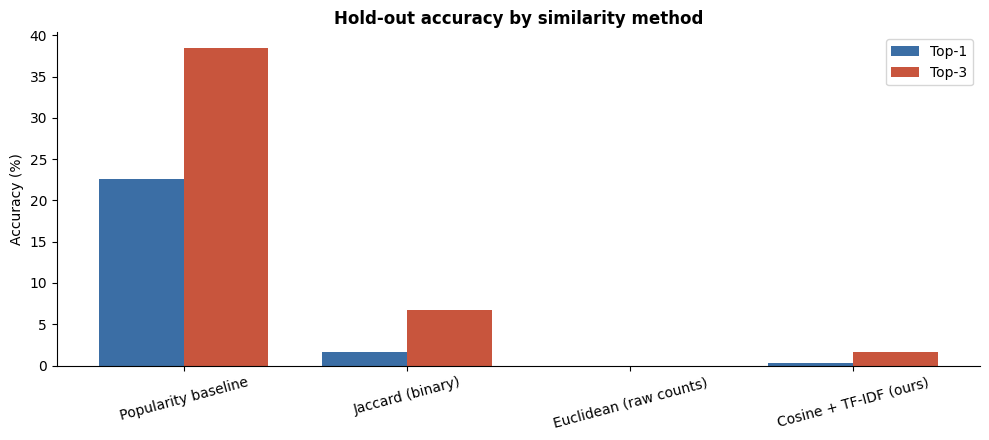

In [30]:
def make_holdout(df: pd.DataFrame, test_frac: float = 0.2, min_postings: int = 5, seed: int = RANDOM_STATE):
    counts = df["job_title"].value_counts()
    pool = df[df["job_title"].isin(counts[counts >= min_postings].index)]
    test = pool.groupby("job_title", group_keys=False).sample(frac=test_frac, random_state=seed)
    return df.drop(test.index), test


def build_queries(test: pd.DataFrame, seed: int = RANDOM_STATE):
    """Turn each held-out posting into a user profile of 3-5 technologies."""
    rng = np.random.default_rng(seed)
    flags = build_tech_flags(test)
    queries, truth = [], []
    for idx in flags.index:
        found = [t for t in TECH_KEYWORDS if flags.at[idx, t]]
        if len(found) >= MIN_SKILLS:
            size = int(rng.integers(MIN_SKILLS, min(len(found), 5) + 1))
            queries.append([str(s) for s in rng.choice(found, size=size, replace=False)])
            truth.append(test.at[idx, "job_title"])
    return queries, truth


def rank_of_truth(sim: np.ndarray, true_idx: np.ndarray) -> np.ndarray:
    """Pessimistic rank (ties count against the model) of the true role for every query."""
    true_scores = sim[np.arange(len(sim)), true_idx]
    return (sim >= true_scores[:, None]).sum(axis=1)


def evaluate_methods(df: pd.DataFrame):
    train, test = make_holdout(df)
    queries, truth = build_queries(test)
    if len(queries) < 10:
        print("Not enough held-out postings with 3+ technologies to evaluate reliably.")
        return None, len(queries)

    engine = TechStackRecommender(train)
    titles = engine.roles["job_title"].tolist()
    true_idx = np.array([titles.index(t) for t in truth])

    cos_sim = np.vstack([engine.score(parse_skills(q)) for q in queries])

    present = (engine.role_tech >= 0.25).to_numpy(dtype=float)                 # roles x technologies
    query_bin = np.array([[float(t in q) for t in TECH_KEYWORDS] for q in queries])
    inter = query_bin @ present.T
    union = query_bin.sum(axis=1, keepdims=True) + present.sum(axis=1)[None, :] - inter
    jaccard_sim = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

    counter = CountVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, ngram_range=(1, 2))
    role_counts = counter.fit_transform(engine.roles["_text"])
    query_counts = np.vstack([sum(counter.transform([s]).toarray() for s in q) for q in queries])
    euclid_sim = -euclidean_distances(query_counts, role_counts)

    popularity = engine.roles["postings"].to_numpy(dtype=float)
    popularity_sim = np.tile(popularity, (len(queries), 1))

    results = {}
    for name, sim in [("Popularity baseline", popularity_sim), ("Jaccard (binary)", jaccard_sim),
                      ("Euclidean (raw counts)", euclid_sim), ("Cosine + TF-IDF (ours)", cos_sim)]:
        ranks = rank_of_truth(sim, true_idx)
        results[name] = {"Top-1": (ranks <= 1).mean(), "Top-3": (ranks <= 3).mean(),
                         "Top-5": (ranks <= 5).mean(), "MRR": (1 / ranks).mean()}
    return pd.DataFrame(results).T, len(queries)


metrics, n_queries = evaluate_methods(jobs)
if metrics is not None:
    print(f"Hold-out queries evaluated: {n_queries}")
    display(metrics.round(3).style.format("{:.1%}", subset=["Top-1", "Top-3", "Top-5"]).format("{:.3f}", subset=["MRR"]))

    fig, ax = plt.subplots(figsize=(10, 4.5))
    width = 0.38
    positions = np.arange(len(metrics))
    ax.bar(positions - width / 2, metrics["Top-1"] * 100, width, label="Top-1", color=PRIMARY)
    ax.bar(positions + width / 2, metrics["Top-3"] * 100, width, label="Top-3", color=ACCENT)
    ax.set_xticks(positions, metrics.index, rotation=15)
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Hold-out accuracy by similarity method")
    ax.legend()
    plt.tight_layout()
    plt.show()

### 8.3 Sample user profiles and sensitivity to experience
Four realistic profiles are scored. The last table keeps the skills fixed and varies only the experience, showing the metadata-driven adjustment.


### Profile: Python Developer  |  skills: python, django, sql

Top 3 recommended career paths
#1  Azure Python Developer   (35.2% match)
     Skills matched : python, django  [2/3]
     Skills to learn: -
     Experience     : 1 yrs    Salary: 87,000 - 93,000
     Open postings  : 1
--------------------------------------------------------------------------
#2  Machine learning Developer   (31.6% match)
     Skills matched : python, django  [2/3]
     Skills to learn: postgresql, machine learning
     Experience     : 2 yrs    Salary: 53,000 - 63,000
     Open postings  : 1
--------------------------------------------------------------------------
#3  Lead Back End Engineer   (30.2% match)
     Skills matched : python, django  [2/3]
     Skills to learn: machine learning
     Experience     : 2 yrs    Salary: 48,500 - 85,000
     Open postings  : 4
--------------------------------------------------------------------------

### Profile: Frontend Developer  |  skills: html, css, javascri

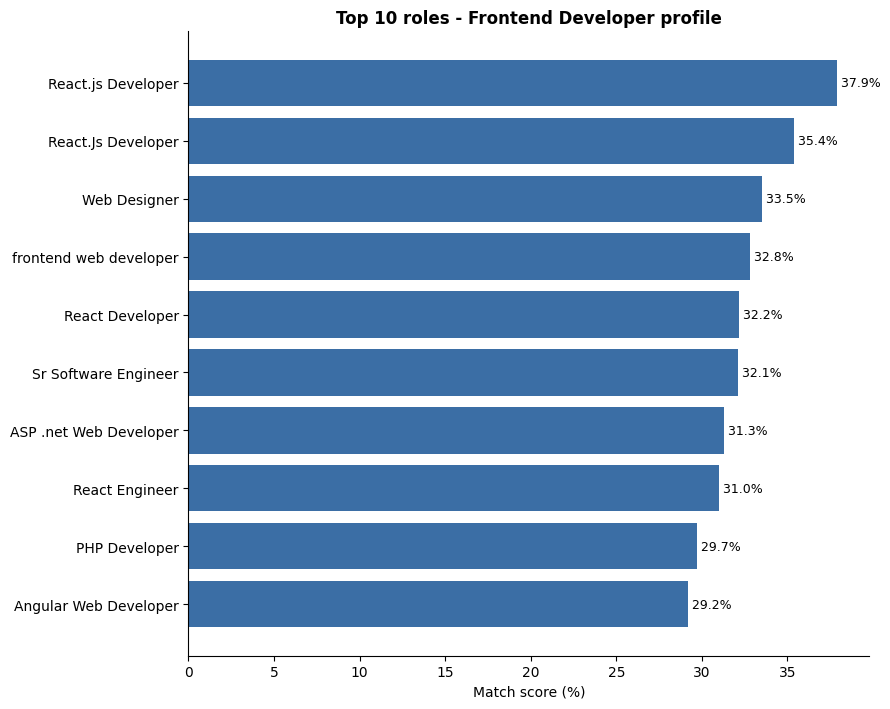


Sensitivity: same skills (python, machine learning, sql), different experience


,#1,#2,#3
0 yrs,Web Analytics,Software Development Engineer,Azure Python Developer
2 yrs,Machine Learning Developer,Machine learning Developer,Principal Software Engineer
5 yrs,Lead Data Scientist,Machine Learning,Lead Python Developer


Sample recommendations saved to ./sample_recommendations.csv


In [31]:
SAMPLE_PROFILES = [
    {"name": "Python Developer",   "skills": ["python", "django", "sql"],                       "experience": 2, "salary": 30000},
    {"name": "Frontend Developer", "skills": ["html", "css", "javascript", "react"],            "experience": 3, "salary": 40000},
    {"name": "Java Developer",     "skills": ["java", "spring", "sql", "hibernate"],            "experience": 4, "salary": 50000},
    {"name": "AI / ML Engineer",   "skills": ["python:5", "machine learning:5", "tensorflow:4", "sql:3"], "experience": 1, "salary": 0},
]

exports = []
for profile in SAMPLE_PROFILES:
    print(f"\n### Profile: {profile['name']}  |  skills: {', '.join(profile['skills'])}")
    sample = recommender.recommend(profile["skills"], experience=profile["experience"], min_salary=profile["salary"])
    display_recommendations(sample)
    exports.append(sample.assign(profile=profile["name"]))

plot_recommendations(
    recommender.recommend(["html", "css", "javascript", "react"], experience=3, min_salary=40000, top_n=10),
    title="Top 10 roles - Frontend Developer profile",
)

print("\nSensitivity: same skills (python, machine learning, sql), different experience")
sensitivity = {
    f"{years} yrs": recommender.recommend(["python", "machine learning", "sql"], experience=years)["job_title"].tolist()
    for years in (0, 2, 5)
}
display(pd.DataFrame.from_dict(sensitivity, orient="index").rename(columns=lambda i: f"#{i + 1}"))

sample_path = os.path.join(OUTPUT_DIR, "sample_recommendations.csv")
pd.concat(exports, ignore_index=True).to_csv(sample_path, index=False)
print(f"Sample recommendations saved to {sample_path}")

## 9. Interactive interface
Enter at least three skills, optionally with a rating from 1 to 5 (for example `python:5, sql:3, docker:2`).
The interest area is only used when none of your skills exist in the dataset (onboarding-survey cold-start bypass).

In [32]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    WIDGETS_AVAILABLE = True
except ImportError:                                   # run `%pip install ipywidgets` in your environment
    WIDGETS_AVAILABLE = False


def build_interface():
    popular = ", ".join(tech_demand[tech_demand > 0].head(12).index)
    hint = widgets.HTML(f"<b>Popular skills in the dataset:</b> {popular}")
    skills_input = widgets.Text(value="python, sql, machine learning",
                                description="Skills:", placeholder="python:5, sql:3, django",
                                layout=widgets.Layout(width="75%"), style={"description_width": "initial"})
    experience_input = widgets.Dropdown(options=[("Skip", None)] + [(f"{y} year{'s' if y != 1 else ''}", y) for y in range(0, 11)],
                                        value=None, description="Experience:", style={"description_width": "initial"})
    salary_input = widgets.IntText(value=0, description="Min salary:", style={"description_width": "initial"})
    interest_input = widgets.Dropdown(options=[("Skip", None)] + [(k, k) for k in INTEREST_PRESETS],
                                      value=None, description="Interest area:", style={"description_width": "initial"})
    top_n_input = widgets.IntSlider(value=TOP_N, min=1, max=10, step=1, description="Top-N:",
                                    style={"description_width": "initial"})
    button = widgets.Button(description="Recommend Career Paths", button_style="success", icon="search")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            profile = parse_skills(skills_input.value)
            if len(profile) < MIN_SKILLS:
                print(f"Please enter at least {MIN_SKILLS} different skills.")
                return
            try:
                results = recommender.recommend(profile, experience=experience_input.value,
                                                min_salary=salary_input.value, top_n=top_n_input.value,
                                                interest=interest_input.value)
            except ValueError as error:
                print(f"Could not generate recommendations: {error}")
                return
            display_recommendations(results)
            plot_recommendations(results, title="Your career recommendations")

    button.on_click(on_click)
    form = widgets.VBox([hint, skills_input, experience_input, salary_input, interest_input, top_n_input, button, output])
    return form, on_click


def run_cli() -> None:
    """Terminal alternative to the widget form (uses input())."""
    print("=== Tech Stack Recommender ===")
    skills = parse_skills(input("Enter at least 3 skills, comma-separated (optional ratings, e.g. python:5): "))
    while len(skills) < MIN_SKILLS:
        skills = parse_skills(input(f"Only {len(skills)} skill(s) entered - please enter at least {MIN_SKILLS}: "))

    def ask_number(prompt):
        value = input(prompt).strip()
        try:
            return float(value) if value else None
        except ValueError:
            print("  Not a number, skipping this filter.")
            return None

    experience = ask_number("Years of experience (Enter to skip): ")
    min_salary = ask_number("Minimum expected salary (Enter to skip): ") or 0
    interest = input(f"Interest area {list(INTEREST_PRESETS)} (Enter to skip): ").strip() or None
    result = recommender.recommend(skills, experience=experience, min_salary=min_salary, interest=interest)
    display_recommendations(result)
    plot_recommendations(result, title="Your career recommendations")


RUN_CLI = False                                       # set True to use the terminal version instead
if WIDGETS_AVAILABLE:
    interface, on_recommend_clicked = build_interface()
    display(interface)
else:
    print("ipywidgets is not installed - run `%pip install ipywidgets`, or set RUN_CLI = True for the terminal version.")
if RUN_CLI:
    run_cli()